# From a salt pulse to stream discharge

This walkthrough reproduces the proposed specific-conductivity result for **Nisqually, October 4, 2026, trial 2**. It follows Kristen Cognac’s Colorado State University R workflow: fit a conductivity correction factor, subtract background, integrate the tracer pulse, and divide the delivered dose by the integral. The calculation gives **2.044 m³/s** for this example. The notebook also checks the effect of the R workflow’s background convention and shows how historical solution-volume estimates were calculated.

Browse [day comparisons](../results/discharge_scenarios/figures/by_day/), [individual trial plots](../results/discharge_scenarios/figures/by_trial/), or the [combined discharge table](../results/discharge_scenarios/figures/plot_estimates.csv).

## Inputs and setup

From the repository root, install the packages in [salt_dilution/requirements.txt](../requirements.txt) and open this notebook in Jupyter. The saved outputs are visible without setup. To rerun from a fresh checkout, export this single recording with the existing parser before opening the notebook. Run from the repository root and use a fresh output directory. Set `recording_dir` in the setup cell to that output directory if it differs from the default.

```sh
python -m salt_dilution.scripts.parsers.parse_data \
  salt_dilution/data/raw/20261004/VuSitu_LiveReadings_2026-10-04_12-24-34_Device_Location.html \
  --output salt_dilution/data/processed/20261004
```

[parse_data.py](../scripts/parsers/parse_data.py) reads the logger exports through [aquatroll.py](../scripts/parsers/aquatroll.py) and [general_logger.py](../scripts/parsers/general_logger.py). It standardizes fields such as timestamps and conductivity. The [field records](../data/records/README.md) supply trial and calibration measurements. [calibration.py](../scripts/processing/calibration.py) derives calibration points and fits each channel. [matching.py](../scripts/processing/matching.py) links the release, recording and candidate fits. See [Getting started](../../docs/getting_started.md) for the preparation and batch commands.

The example uses a saved recording link and saved analysis windows. Here, clock readings use fixed PST (UTC−08:00). The integral uses elapsed seconds, so the time-zone convention matters for matching the release to the recording.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project = next(path for path in (Path.cwd(), *Path.cwd().parents)
               if (path / "salt_dilution" / "scripts").is_dir())
salt = project / "salt_dilution"
results = salt / "results"
scenario = results / "discharge_scenarios"
figures = scenario / "figures"

trial_id = "NISQ-20261004-T02"
channel = "specific"
recording_dir = salt / "data/processed/20261004"

selected = pd.read_csv(results / "discharge_analysis/tables/discharge_estimates.csv")
estimate = selected.query("trial_id == @trial_id and conductivity_basis == @channel").squeeze(axis=0)
fit_ref = json.loads(estimate.fit_reference)
calibration_id, series, _ = fit_ref["key"]
calibration_run = project / fit_ref["run_path"]

## 1. Fit the correction factor (K)

Each aliquot adds a known amount of salt to the calibration vessel. Divide the cumulative added salt mass by the **current** vessel volume to get added concentration. In this calibration, the stock was prepared with 1 g of salt and 1,000 mL of starting river water. Using that water volume as the stock volume gives 1,000 mg/L for the stock. The receiver started at 2,000 mL.

Fit added concentration (mg/L) against specific conductivity (µS/cm), with a free intercept, as in [Cognac’s R workflow](../data/raw/wrd_sample/MORA_Salt_Slugs.Rmd). The slope (K) converts **changes** in conductivity to changes in concentration. The intercept cancels when taking a difference. Fit standard error measures slope precision for these points. It leaves out stock volume, mixing, and other field uncertainties.

In [2]:
points = pd.read_csv(calibration_run / "calibration_points.csv")
calibration = points.query(
    "calibration_id == @calibration_id and probe_alias == @series "
    "and conductivity_basis == @channel and used_in_fit"
).sort_values("step_no")
conductivity = calibration.conductivity_us_cm.to_numpy()
added_concentration = (
    1000 * calibration.cumulative_added_volume_ml / calibration.calculated_vessel_volume_ml
)

(slope, intercept), covariance = np.polyfit(conductivity, added_concentration, 1, cov=True)
slope_se = np.sqrt(covariance[0, 0])
np.testing.assert_allclose(added_concentration, calibration.concentration, rtol=1e-10)
np.testing.assert_allclose([slope, slope_se], [estimate.k, estimate.k_se], rtol=1e-10)
print(f"{len(calibration)} observations | K = {slope:.6f} ± {slope_se:.6f} (fit SE) "
      "(mg/L)/(µS/cm)")

10 observations | K = 0.385755 ± 0.001835 (fit SE) (mg/L)/(µS/cm)


## 2. Subtract background and integrate the pulse

Take the mean conductivity in the saved pre- and post-pulse windows. Draw a straight line between those means at their mean times. Subtract that background from each pulse observation, then integrate the signed excess with the trapezoid rule. Each trapezoid uses the **recorded** time between its two observations.

Cognac’s R example uses a constant pre-pulse background, clips negative excess to zero, and uses a fixed step, normally 1 s. Those are reasonable choices for the intended continuously sampled logs. This project allows a changing background and retains signed excess. This worked recording has uninterrupted 1 s samples in the analysis window. For other trials, a pause before tracer arrival can leave the pulse intact. A gap during the pulse needs separate treatment and is flagged in the scenario results.

In [3]:
recording_path = recording_dir / "VuSitu_LiveReadings_2026-10-04_12-24-34_Device_Location.csv"
if not recording_path.is_file():
    raise FileNotFoundError(f"Add the approved normalized recording at {recording_path}")
recording = pd.read_csv(recording_path, usecols=["timestamp", "specific_conductivity_us_cm"])
recording["seconds"] = (
    pd.to_datetime(recording.timestamp) - pd.Timestamp(estimate.recording_origin_local)
).dt.total_seconds()
windows = json.loads(estimate.windows)
pre, pulse, post = [
    recording.loc[recording.seconds.between(*windows[name])]
    for name in ("pre", "pulse", "post")
]
time = pulse.seconds.to_numpy()
observed = pulse.specific_conductivity_us_cm.to_numpy()
np.testing.assert_array_equal(np.diff(time), 1)
background = np.interp(
    time, [pre.seconds.mean(), post.seconds.mean()],
    [pre.specific_conductivity_us_cm.mean(), post.specific_conductivity_us_cm.mean()],
)
area = np.trapezoid(observed - background, x=time)
np.testing.assert_allclose(area, estimate.integral_us_cm_s, rtol=1e-10)
print(f"{len(pulse)} pulse observations | Integrated excess = {area:,.2f} (µS/cm)·s")

306 pulse observations | Integrated excess = 5,073.47 (µS/cm)·s


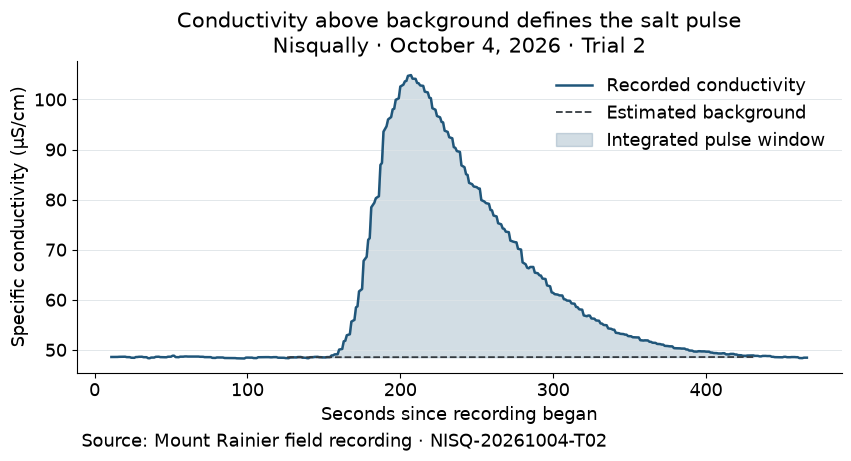

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 4.5), layout="constrained")
analysis_window = recording.loc[recording.seconds.between(windows["pre"][0], windows["post"][1])]
ax.plot(analysis_window.seconds, analysis_window.specific_conductivity_us_cm,
        color="#20567A", linewidth=1.8, label="Recorded conductivity")
ax.plot(time, background, color="#343A40", linestyle="--", linewidth=1.3, label="Estimated background")
ax.fill_between(time, background, observed, color="#20567A", alpha=0.20,
                label="Integrated pulse window")
ax.set(title="Conductivity above background defines the salt pulse\nNisqually · October 4, 2026 · Trial 2",
       xlabel="Seconds since recording began", ylabel="Specific conductivity (µS/cm)")
ax.grid(axis="y", linewidth=0.6, color="#DDE3E7")
ax.spines[["top", "right"]].set_visible(False)
ax.title.set_fontsize(15)
ax.xaxis.label.set_fontsize(13)
ax.yaxis.label.set_fontsize(13)
ax.tick_params(labelsize=13)
ax.legend(frameon=False, loc="upper right", fontsize=13)
fig.supxlabel("Source: Mount Rainier field recording · NISQ-20261004-T02",
              fontsize=13, x=0.09, ha="left")
plt.show()

The shaded region marks the saved integration window. Observed conductivity rises, peaks and returns close to the dashed background. The calculation retains small negative differences where the signal dips below background.

## 3. Convert the pulse area to discharge

For the mass method, multiply the conductivity integral (A) by (K) to get the time integral of added salt concentration, in mg·s/L. Divide the delivered mass in mg by that quantity for L/s, then divide by 1,000 for m³/s. A field participant confirmed 4,000 g entered the river for this trial.

The background and some pulse observations fall below the lowest calibration point. The calculation reproduces the saved estimate, which remains proposed. Suitable mixing and full tracer recovery are field assumptions.

In [5]:
concentration_area = slope * area
q_l_s = (estimate.mass_g * 1000) / concentration_area
q_m3_s = q_l_s / 1000
np.testing.assert_allclose([q_l_s, q_m3_s], [estimate.q_l_s, estimate.q_m3_s], rtol=1e-10)
print(f"Concentration integral: {concentration_area:,.2f} mg·s/L")
print(f"Discharge: {q_l_s:,.2f} L/s = {q_m3_s:.3f} m³/s")
print(f"Background: {background.mean():.1f} µS/cm | Calibration: "
      f"{conductivity.min():.1f}–{conductivity.max():.1f} µS/cm")

Concentration integral: 1,957.12 mg·s/L
Discharge: 2,043.82 L/s = 2.044 m³/s
Background: 48.5 µS/cm | Calibration: 50.2–109.0 µS/cm


To isolate the background and integration choices, apply the R example's constant pre-pulse background and zero clipping to the **same** samples and K. The calculation below uses the same 1 s step as this recording. This comparison holds the pulse window fixed, so it does not test the R workflow's automatic event detection.

In [6]:
clamped_excess = np.maximum(observed - pre.specific_conductivity_us_cm.mean(), 0)
reference_area = np.trapezoid(clamped_excess, dx=1.0)
reference_q = estimate.mass_g / (slope * reference_area)
print(f"Constant background and clipped excess: {reference_q:.3f} m³/s "
      f"({reference_q / q_m3_s - 1:+.2%} versus the saved estimate)")

Constant background and clipped excess: 2.040 m³/s (-0.18% versus the saved estimate)


### When the recorded dose is a solution volume

Some historical records support a solution-volume calculation. In that case (K) converts excess conductivity to the volume fraction of original solution in streamwater, rather than to mg/L. Multiplying (K) by (A) gives the integrated fraction, in seconds. Divide the delivered original solution volume in m³ by that integral. The recipe must link the calibration stock to the injected solution, including any secondary dilution. July 24 trial 1 uses its reported 12.9 L with delivery assumed, and transfer of the calibration between devices is unverified.

In [7]:
working = pd.read_csv(scenario / "working_estimates.csv")
volume_example = working.query(
    "trial_id == 'NISQ-20250724-T01' and window_id == 'window_003' "
    "and conductivity_basis == @channel"
).squeeze(axis=0)
assert volume_example.coefficient_unit == "(mL/mL) / (uS/cm)"
volume_m3 = volume_example.injection_solution_volume_ml / 1_000_000
volume_q_m3_s = volume_m3 / (volume_example.k * volume_example.integral_us_cm_s)
np.testing.assert_allclose(volume_q_m3_s, volume_example.q_m3_s, rtol=1e-10)
print(f"July 24, 2025 · Trial 1: {volume_q_m3_s:.3f} m³/s (conditional)")

July 24, 2025 · Trial 1: 6.672 m³/s (conditional)


## 4. Read the results across releases

[mass_slug.py](../scripts/processing/mass_slug.py) calculates the selected-run estimates. [discharge_scenarios.py](../scripts/processing/discharge_scenarios.py) evaluates alternate or inferred recipes, dose evidence, and pulse-window treatments. The [table guide](../results/discharge_scenarios/README.md) explains how to join each result to its recording, channel, calibration and assumptions.

The counts below are **releases**, while the combined table retains each instrument/channel/calibration estimate. Keep those distinctions when comparing values. A blank release-level Q can reflect unresolved delivery or calibration evidence. The September 3 spill has a response per litre, since its delivered volume is unknown.

In [8]:
combined = pd.read_csv(figures / "plot_estimates.csv")
coverage = pd.read_csv(figures / "release_coverage.csv")
experimental = coverage.loc[coverage.plot_status != "excluded_practice"]
counts = experimental.assign(has_q=experimental.plotted_q_count.gt(0)).groupby("site")[
    "has_q"
].agg(releases="size", with_q="sum")
counts["without_q"] = counts.releases - counts.with_q

worked_example = combined.query("trial_id == @trial_id and conductivity_basis == @channel").squeeze(axis=0)
np.testing.assert_allclose(worked_example.q_m3_s, q_m3_s, rtol=1e-10)
np.testing.assert_array_equal(
    coverage.set_index("trial_id").plotted_q_count,
    combined.groupby("trial_id").size().reindex(coverage.trial_id, fill_value=0),
)
print(f"{counts.with_q.sum()} of {counts.releases.sum()} experimental releases have a Q estimate.")
print(f"{experimental.plot_status.eq('working_conditional').sum()} releases have working conditional estimates.")
print(f"The combined table contains {len(combined)} individual estimates across channels and fits.")
counts.rename(index={"NISQ": "Nisqually", "PAR": "Paradise"},
              columns={"releases": "Experimental releases", "with_q": "With Q", "without_q": "Without Q"})

33 of 36 experimental releases have a Q estimate.
22 releases have working conditional estimates.
The combined table contains 79 individual estimates across channels and fits.


,Experimental releases,With Q,Without Q
site,,,
Nisqually,30,27,3
Paradise,6,6,0


## References

- Kristen Cognac, Colorado State University. *MORA Salt Slugs*, R workflow and rendered report supplied in the October 1, 2026 “Salt Gauging – Next Steps for MORA” correspondence. [R source](../data/raw/wrd_sample/MORA_Salt_Slugs.Rmd) · [rendered report](../data/raw/wrd_sample/MORA_Salt_Slugs.html)
- Moore, R. D. (2005). *Slug injection using salt in solution*. Streamline Watershed Management Bulletin, 8(2), 1–6. [Project methods and references](../../docs/research_methods.md)